# Where Should My Uncle Buy a Home in the U.S.?
### A housing market analysis of 7 U.S. markets (2012–2025) using Redfin data

**Background**
Over Lunar New Year dinner, my uncle mentioned he is planning to retire, travel the world, and move to the U.S. to be closer to family. His questions were simple: *Where can I afford to live? Is it too expensive?*

This project uses Redfin market data to see what the numbers say.

**Scope**
This analysis covers housing market conditions only: price, price trend, how competitive each market is, and supply.
Cost of living, property tax, and community demographics are out of scope and listed as future work.

In [1]:
#packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
#Redfin csv
RF_df = pd.read_csv('/content/drive/MyDrive/Project portfolio/Housing project/Redfin_data.csv')
RF_df.head()

,Region,Month of Period End,Median Sale Price,Median Sale Price MoM,Median Sale Price YoY,Homes Sold,Homes Sold MoM,Homes Sold YoY,New Listings,New Listings MoM,New Listings YoY,Inventory,Inventory MoM,Inventory YoY,Days on Market,Days on Market MoM,Days on Market YoY,Average Sale To List,Average Sale To List MoM,Average Sale To List YoY
0,"Austin, TX metro area",January 2012,$180K,-5.3%,-2.8%,"1,181",-29.7%,13.6%,"2,167",63.1%,-3.7%,"6,871",-0.6%,-21.3%,74,-3,-15,96.2%,-0.2%,0.3%
1,"Austin, TX metro area",February 2012,$190K,5.6%,2.3%,"1,397",18.3%,16.4%,"2,559",18.1%,10.2%,"6,975",1.5%,-21.6%,73,-1,-20,96.7%,0.5%,0.1%
2,"Austin, TX metro area",March 2012,$200K,5.2%,8.8%,"2,071",48.2%,18.8%,"3,392",32.6%,-3.2%,"7,429",6.5%,-23.0%,58,-15,-27,97.3%,0.6%,0.9%
3,"Austin, TX metro area",April 2012,$205K,2.6%,7.9%,"2,118",2.3%,15.0%,"3,376",-0.5%,1.2%,"7,737",4.1%,-23.9%,38,-20,-24,97.7%,0.4%,0.9%
4,"Austin, TX metro area",May 2012,$210K,2.4%,9.4%,"2,580",21.8%,25.2%,"3,490",3.4%,12.1%,"7,968",3.0%,-22.3%,36,-2,-18,97.7%,0.0%,1.0%


## 1. Data Overview
Basic checks on the raw data: size, data types, missing values, duplicate rows, and whether every region has the same amount of data.

In [4]:
#how many rows and columns
RF_df.shape

(1336, 20)

In [5]:
#data type of each column
RF_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1336 entries, 0 to 1335
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Region                     1336 non-null   object
 1   Month of Period End        1336 non-null   object
 2   Median Sale Price          1336 non-null   object
 3   Median Sale Price MoM      1336 non-null   object
 4   Median Sale Price YoY      1336 non-null   object
 5   Homes Sold                 1336 non-null   object
 6   Homes Sold MoM             1336 non-null   object
 7   Homes Sold YoY             1336 non-null   object
 8   New Listings               1336 non-null   object
 9   New Listings MoM           1336 non-null   object
 10  New Listings YoY           1336 non-null   object
 11  Inventory                  1336 non-null   object
 12  Inventory MoM              1336 non-null   object
 13   Inventory YoY             1336 non-null   object
 14  Days on 

In [6]:
#missing values in each column
print(RF_df.isnull().sum())

Region                       0
Month of Period End          0
Median Sale Price            0
Median Sale Price MoM        0
Median Sale Price YoY        0
Homes Sold                   0
Homes Sold MoM               0
Homes Sold YoY               0
New Listings                 0
New Listings MoM             0
New Listings YoY             0
Inventory                    0
Inventory MoM                0
 Inventory YoY               0
Days on Market               0
Days on Market MoM           0
Days on Market YoY           0
Average Sale To List         0
Average Sale To List MoM     0
Average Sale To List YoY     0
dtype: int64


In [7]:
#duplicated rows
print("Duplicated rows:", RF_df.duplicated().sum())

Duplicated rows: 0


In [8]:
#rows per region
print(RF_df['Region'].value_counts())

Region
Austin, TX metro area           167
Berkeley, CA                    167
Dallas, TX                      167
Dallas, TX metro area           167
Los Angeles, CA metro area      167
San Diego, CA metro area        167
San Francisco, CA metro area    167
San Jose, CA metro area         167
Name: count, dtype: int64


## 2. Data Cleaning
The info() output above shows 17 of 20 columns are stored as text (object), even though most of them hold numbers. Each step below follows the same order: inspect, fix, verify.

In [9]:
#inspect column names
print(list(RF_df.columns))

['Region', 'Month of Period End', 'Median Sale Price', 'Median Sale Price MoM ', 'Median Sale Price YoY ', 'Homes Sold', 'Homes Sold MoM ', 'Homes Sold YoY ', 'New Listings', 'New Listings MoM ', 'New Listings YoY ', 'Inventory', 'Inventory MoM ', ' Inventory YoY ', 'Days on Market', 'Days on Market MoM', 'Days on Market YoY', 'Average Sale To List', 'Average Sale To List MoM ', 'Average Sale To List YoY ']


In [10]:
#remove hidden spaces in column names (e.g. 'Median Sale Price MoM ' has a trailing space), then verify
RF_df.columns = RF_df.columns.str.strip()
print(list(RF_df.columns))

['Region', 'Month of Period End', 'Median Sale Price', 'Median Sale Price MoM', 'Median Sale Price YoY', 'Homes Sold', 'Homes Sold MoM', 'Homes Sold YoY', 'New Listings', 'New Listings MoM', 'New Listings YoY', 'Inventory', 'Inventory MoM', 'Inventory YoY', 'Days on Market', 'Days on Market MoM', 'Days on Market YoY', 'Average Sale To List', 'Average Sale To List MoM', 'Average Sale To List YoY']


In [11]:
#inspect one full row to see how values are stored
RF_df.iloc[0]

,0
Region,"Austin, TX metro area"
Month of Period End,January 2012
Median Sale Price,$180K
Median Sale Price MoM,-5.3%
Median Sale Price YoY,-2.8%
Homes Sold,"1,181"
Homes Sold MoM,-29.7%
Homes Sold YoY,13.6%
New Listings,"2,167"
New Listings MoM,63.1%


### What the raw values look like
One row reveals four text formats that need converting:
- **Dates** stored as text: "January 2012"
- **Prices** with \$ and K: "\$180K"
- **Rates** with %: "-5.3%", "96.2%"
- **Counts** with commas: "1,181"

Days on Market columns are already numeric and need no cleaning.

In [12]:
#fix dates: convert text to datetime, then create Month and Year columns
RF_df['Month of Period End'] = pd.to_datetime(RF_df['Month of Period End'], format='%B %Y')
RF_df['Month'] = RF_df['Month of Period End'].dt.month
RF_df['Year'] = RF_df['Month of Period End'].dt.year

#verify
print(RF_df[['Month of Period End', 'Month', 'Year']].head(3))
print(RF_df['Month of Period End'].dtype)

  Month of Period End  Month  Year
0          2012-01-01      1  2012
1          2012-02-01      2  2012
2          2012-03-01      3  2012
datetime64[ns]


In [13]:
#find every column that contains a % sign
percent_columns = []
for col in RF_df.columns:
    if RF_df[col].astype(str).str.contains('%').any():
        percent_columns.append(col)

print(len(percent_columns), "columns contain %:")
print(percent_columns)

11 columns contain %:
['Median Sale Price MoM', 'Median Sale Price YoY', 'Homes Sold MoM', 'Homes Sold YoY', 'New Listings MoM', 'New Listings YoY', 'Inventory MoM', 'Inventory YoY', 'Average Sale To List', 'Average Sale To List MoM', 'Average Sale To List YoY']


In [14]:
#fix rates: remove % and convert to decimals (96.2% becomes 0.962)
for col in percent_columns:
    RF_df[col] = RF_df[col].astype(str).str.replace('%', '', regex=False)
    RF_df[col] = pd.to_numeric(RF_df[col], errors='coerce') / 100

#verify
print(RF_df[percent_columns].isnull().sum().sum(), "missing values created")
print(RF_df[['Average Sale To List', 'Median Sale Price YoY']].head(3))

0 missing values created
   Average Sale To List  Median Sale Price YoY
0                 0.962                 -0.028
1                 0.967                  0.023
2                 0.973                  0.088


In [15]:
#check price units: do all prices end in K, or are some in M (millions)?
print(RF_df['Median Sale Price'].str[-1].value_counts())

Median Sale Price
K    1336
Name: count, dtype: int64


In [16]:
#fix prices: remove $, K and comma, so price is in thousands of dollars ($K)
RF_df['Median Sale Price'] = RF_df['Median Sale Price'].astype(str) \
    .str.replace('$', '', regex=False) \
    .str.replace('K', '', regex=False) \
    .str.replace(',', '', regex=False)
RF_df['Median Sale Price'] = pd.to_numeric(RF_df['Median Sale Price'], errors='coerce')

#verify
print(RF_df['Median Sale Price'].head(3))
print(RF_df['Median Sale Price'].isnull().sum(), "missing values created")

0    180
1    190
2    200
Name: Median Sale Price, dtype: int64
0 missing values created


In [17]:
#which columns are still text? (Region is supposed to be text)
for col in RF_df.columns:
    if RF_df[col].dtype == 'object' and col != 'Region':
        print(col, '->', RF_df[col].iloc[0])

Homes Sold -> 1,181
New Listings -> 2,167
Inventory -> 6,871


In [18]:
#fix counts: remove commas and convert to numbers
count_columns = ['Homes Sold', 'New Listings', 'Inventory']

for col in count_columns:
    RF_df[col] = RF_df[col].astype(str).str.replace(',', '', regex=False)
    RF_df[col] = pd.to_numeric(RF_df[col], errors='coerce')

#verify
print(RF_df[count_columns].head(3))

   Homes Sold  New Listings  Inventory
0        1181          2167       6871
1        1397          2559       6975
2        2071          3392       7429


In [19]:
#final check: no missing values created, and only Region is still text
print(RF_df.isnull().sum().sum(), "missing values after cleaning")
RF_df.info()

0 missing values after cleaning
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1336 entries, 0 to 1335
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Region                    1336 non-null   object        
 1   Month of Period End       1336 non-null   datetime64[ns]
 2   Median Sale Price         1336 non-null   int64         
 3   Median Sale Price MoM     1336 non-null   float64       
 4   Median Sale Price YoY     1336 non-null   float64       
 5   Homes Sold                1336 non-null   int64         
 6   Homes Sold MoM            1336 non-null   float64       
 7   Homes Sold YoY            1336 non-null   float64       
 8   New Listings              1336 non-null   int64         
 9   New Listings MoM          1336 non-null   float64       
 10  New Listings YoY          1336 non-null   float64       
 11  Inventory                 1336 non-null   int64   

## 3. Overlapping Regions
The region list in Section 1 shows both "Dallas, TX" (the city) and "Dallas, TX metro area". The metro area includes the city, so the two overlap.

In [20]:
#Dallas city vs Dallas metro: how far apart are the median prices?
dallas = RF_df.pivot_table(index='Month of Period End', columns='Region', values='Median Sale Price')
gap = (dallas['Dallas, TX'] - dallas['Dallas, TX metro area']).abs()
print("Average gap ($K):", round(gap.mean(), 1))

Average gap ($K): 23.0


In [21]:
#keep the metro area only, drop Dallas city to avoid double counting
RF_df = RF_df[RF_df['Region'] != 'Dallas, TX']
print(RF_df.shape)
print(RF_df['Region'].unique())

(1169, 22)
['Austin, TX metro area' 'Berkeley, CA' 'Dallas, TX metro area'
 'Los Angeles, CA metro area' 'San Diego, CA metro area'
 'San Francisco, CA metro area' 'San Jose, CA metro area']


### Data quality summary

- **No missing values and no duplicates.** Every region has exactly 167 monthly rows (Jan 2012 to Nov 2025), so all regions are compared over the same time window.
- **Everything was stored as text.** Prices looked like "\$180K", rates like "96.2%", and counts like "2,167". All were converted to numbers. Prices are in thousands of dollars (\$K), and percentages are decimals (0.962 = 96.2%).
- **Hidden spaces in column names.** For example, "Median Sale Price MoM " had a trailing space. Column names are stripped first, otherwise column lookups fail.
- **Dallas appears twice.** "Dallas, TX" (city) and "Dallas, TX metro area" overlap, and their median prices are only about \$23K apart on average. Keeping both would count Dallas twice, so only the metro area is kept to match the other regions.
- **Berkeley is a city, not a metro area.** It is the only city-level region left, so comparisons with it should be read with that in mind.

**Result:** 7 regions x 167 months = 1,169 clean rows.

## 4. Distributions and Outliers
Before answering the main questions, this section checks the shape of the key variables: is anything skewed, and who holds the extreme values?

Note: each row is one region in one month, not one house. An "outlier" here means an unusual month for a market, not an unusual home.
All analysis in this section runs on a copy of the data, so the main dataset stays unchanged.

In [22]:
#work on a copy so this section does not change RF_df
dist_df = RF_df.copy()

#the five variables used in the rest of the analysis
key_columns = ['Median Sale Price', 'Days on Market', 'Average Sale To List', 'Inventory', 'Homes Sold']

In [23]:
#summary statistics
dist_df[key_columns].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Median Sale Price,1169.0,770.10,428.21,152.00,419.00,682.0,1139.00,1785.00
Days on Market,1169.0,29.29,15.56,8.00,16.00,26.0,38.00,100.00
Average Sale To List,1169.0,1.03,0.06,0.96,0.98,1.0,1.05,1.37
Inventory,1169.0,6774.94,6315.60,27.00,1467.00,5287.0,11653.00,28397.00
Homes Sold,1169.0,2682.78,2114.08,15.00,981.00,2277.0,4071.00,8498.00


In [24]:
#skewness: 0 = symmetric, above 0 = right-tailed (long tail of high values), below 0 = left-tailed
print(dist_df[key_columns].skew().round(2).sort_values(ascending=False))

Average Sale To List    1.65
Days on Market          1.21
Inventory               0.81
Homes Sold              0.60
Median Sale Price       0.46
dtype: float64


In [25]:
#fixed color for each region, used in every chart (Texas = warm colors, California = cool colors)
region_colors = {
    'Austin, TX metro area': '#eb6834',
    'Dallas, TX metro area': '#eda100',
    'Los Angeles, CA metro area': '#2a78d6',
    'San Diego, CA metro area': '#1baf7a',
    'San Francisco, CA metro area': '#6250d6',
    'San Jose, CA metro area': '#e87ba4',
    'Berkeley, CA': '#008300'
}

#region order from cheapest to most expensive (by median price), used in the charts below
region_order = dist_df.groupby('Region')['Median Sale Price'].median().sort_values().index

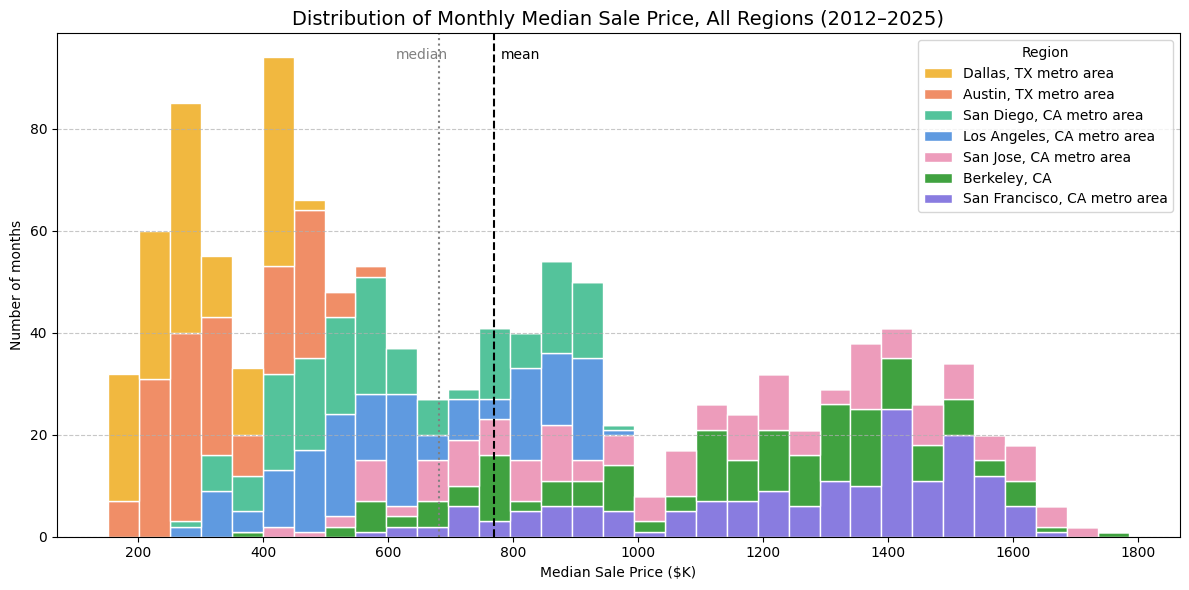

In [26]:
#histogram of price, stacked by region: who is in the right tail?
plt.figure(figsize=(12,6))
sns.histplot(data=dist_df,
             x='Median Sale Price',
             hue='Region',
             hue_order=region_order,
             palette=region_colors,
             multiple='stack',
             binwidth=50,
             edgecolor='white')
plt.axvline(dist_df['Median Sale Price'].mean(), color='black', linestyle='--', linewidth=1.5)
plt.axvline(dist_df['Median Sale Price'].median(), color='gray', linestyle=':', linewidth=1.5)
plt.text(dist_df['Median Sale Price'].mean() + 10, plt.ylim()[1] * 0.95, 'mean', fontsize=10)
plt.text(dist_df['Median Sale Price'].median() - 70, plt.ylim()[1] * 0.95, 'median', fontsize=10, color='gray')
plt.title('Distribution of Monthly Median Sale Price, All Regions (2012–2025)', fontsize=14)
plt.xlabel('Median Sale Price ($K)')
plt.ylabel('Number of months')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [27]:
#price statistics within each region
dist_df.groupby('Region')['Median Sale Price'].agg(['mean', 'median', 'std', 'min', 'max', 'skew']).round(1).sort_values('median')

,mean,median,std,min,max,skew
Region,,,,,,
"Dallas, TX metro area",302.7,288.0,87.8,152,462,0.2
"Austin, TX metro area",338.6,310.0,97.6,180,555,0.3
"San Diego, CA metro area",616.8,575.0,185.8,300,949,0.3
"Los Angeles, CA metro area",643.4,625.0,185.8,290,950,0.0
"San Jose, CA metro area",1095.3,1100.0,336.2,425,1700,-0.0
"Berkeley, CA",1137.7,1200.0,297.6,376,1785,-0.4
"San Francisco, CA metro area",1256.4,1350.0,274.2,562,1680,-0.8


In [28]:
#are there any price outliers across all regions? (IQR method)
q1 = dist_df['Median Sale Price'].quantile(0.25)
q3 = dist_df['Median Sale Price'].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
lower_fence = q1 - 1.5 * iqr

print("Lower fence ($K):", lower_fence)
print("Upper fence ($K):", upper_fence)
print("Highest price in the data ($K):", dist_df['Median Sale Price'].max())
print("Number of price outliers:", ((dist_df['Median Sale Price'] > upper_fence) | (dist_df['Median Sale Price'] < lower_fence)).sum())

Lower fence ($K): -661.0
Upper fence ($K): 2219.0
Highest price in the data ($K): 1785
Number of price outliers: 0


### Finding: the right tail is not a few outliers, it is the Bay Area
- **Price is right-skewed overall:** the mean (\$770K) is above the median (\$682K).
- **The histogram shows why.** The data forms three groups: Texas (\$150K to \$550K), Southern California (\$290K to \$950K), and the Bay Area (Berkeley, San Francisco, San Jose), which forms the long right tail up to \$1.8M.
- **The IQR method finds zero price outliers.** The highest price in the data is below the upper fence, so no single month is extreme. The skew comes from mixing markets that are priced completely differently.
- **Within each region, price is close to symmetric** (skew between -0.8 and 0.3). This is why every comparison from here on is done region by region, not on the pooled data.

In [29]:
#who holds the extreme values? (highest and lowest month for each variable)
for col in key_columns:
    max_row = dist_df.loc[dist_df[col].idxmax()]
    min_row = dist_df.loc[dist_df[col].idxmin()]
    print(col)
    print("   highest:", max_row[col], "-", max_row['Region'], max_row['Month of Period End'].strftime('%b %Y'))
    print("   lowest: ", min_row[col], "-", min_row['Region'], min_row['Month of Period End'].strftime('%b %Y'))

Median Sale Price
   highest: 1785 - Berkeley, CA Apr 2022
   lowest:  152 - Dallas, TX metro area Jan 2012
Days on Market
   highest: 100 - Austin, TX metro area Feb 2025
   lowest:  8 - San Jose, CA metro area Feb 2022
Average Sale To List
   highest: 1.371 - Berkeley, CA Apr 2022
   lowest:  0.96 - Austin, TX metro area Dec 2022
Inventory
   highest: 28397 - Dallas, TX metro area Jul 2025
   lowest:  27 - Berkeley, CA Dec 2019
Homes Sold
   highest: 8498 - Dallas, TX metro area Jul 2020
   lowest:  15 - Berkeley, CA Jan 2015


In [30]:
#outlier months within each region (IQR method), for Days on Market and Sale-to-List
for col in ['Days on Market', 'Average Sale To List']:
    print("=====", col, "=====")
    for region in region_order:
        region_data = dist_df[dist_df['Region'] == region]
        q1 = region_data[col].quantile(0.25)
        q3 = region_data[col].quantile(0.75)
        iqr = q3 - q1
        outliers = region_data[(region_data[col] < q1 - 1.5 * iqr) | (region_data[col] > q3 + 1.5 * iqr)]
        if len(outliers) > 0:
            print(region, "-", len(outliers), "outlier months, in years:", sorted(outliers['Year'].unique().tolist()))
    print()

===== Days on Market =====
Dallas, TX metro area - 2 outlier months, in years: [2012]
Austin, TX metro area - 6 outlier months, in years: [2024, 2025]
San Diego, CA metro area - 2 outlier months, in years: [2012]
Los Angeles, CA metro area - 6 outlier months, in years: [2012, 2013]
San Jose, CA metro area - 3 outlier months, in years: [2012, 2019, 2020]
Berkeley, CA - 44 outlier months, in years: [2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
San Francisco, CA metro area - 11 outlier months, in years: [2012, 2017, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

===== Average Sale To List =====
Dallas, TX metro area - 17 outlier months, in years: [2021, 2022]
Austin, TX metro area - 18 outlier months, in years: [2021, 2022]
San Diego, CA metro area - 14 outlier months, in years: [2021, 2022]
Los Angeles, CA metro area - 15 outlier months, in years: [2021, 2022]
San Jose, CA metro area - 6 outlier months, in years: [2018, 2022]
Berkeley, CA - 4 outlier mo

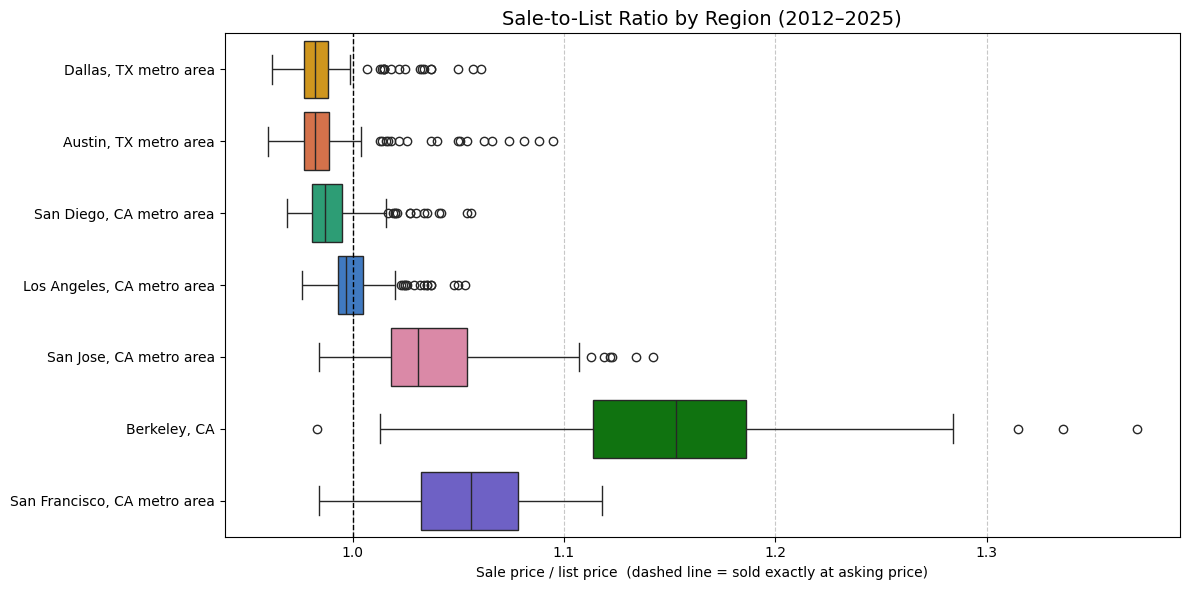

In [31]:
#boxplot of Sale-to-List by region: each dot is an outlier month
plt.figure(figsize=(12,6))
sns.boxplot(data=dist_df,
            x='Average Sale To List',
            y='Region',
            order=region_order,
            hue='Region',
            palette=region_colors,
            legend=False)
plt.axvline(1.0, color='black', linestyle='--', linewidth=1)
plt.title('Sale-to-List Ratio by Region (2012–2025)', fontsize=14)
plt.xlabel('Sale price / list price  (dashed line = sold exactly at asking price)')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Finding: the outliers are real market events, not data errors
- **The 2021–2022 bidding wars show up as outliers.** In Austin, Dallas, LA and San Diego, every Sale-to-List outlier falls in 2021 or 2022, when homes regularly sold above asking. Those are the dots on the right of each box.
- **Austin's slow market today is unusual even for Austin.** Its Days on Market outliers all fall in late 2024 and 2025, and February 2025 hit 100 days, the slowest month of any market in the data.
- **Berkeley lives in its own world.** Its typical home sells for about 15% over asking, and April 2022 holds both the highest price (\$1,785K) and the highest Sale-to-List ratio (1.37) in the whole dataset.
- **Decision: no outliers are removed.** They reflect real events (the 2021 frenzy, the 2022 peak, the 2025 slowdown), which are exactly what the rest of this analysis is about.

## 5. Q1: How expensive is each market, and how much have prices grown?
Median sale price per region, from January 2012 to November 2025.

In [32]:
#average median price in 2012 vs 2025, and how many times it grew
yearly_price = RF_df.groupby(['Region', 'Year'])['Median Sale Price'].mean().unstack()

price_table = pd.DataFrame()
price_table['2012 ($K)'] = yearly_price[2012].round(0)
price_table['2025 ($K)'] = yearly_price[2025].round(0)
price_table['Growth (x)'] = (yearly_price[2025] / yearly_price[2012]).round(1)

price_table = price_table.sort_values('2025 ($K)', ascending=False)
print("Note: 2025 covers January to November")
price_table

Note: 2025 covers January to November


,2012 ($K),2025 ($K),Growth (x)
Region,,,
"San Jose, CA metro area",538.0,1610.0,3.0
"San Francisco, CA metro area",688.0,1514.0,2.2
"Berkeley, CA",573.0,1415.0,2.5
"Los Angeles, CA metro area",328.0,916.0,2.8
"San Diego, CA metro area",336.0,905.0,2.7
"Austin, TX metro area",202.0,435.0,2.2
"Dallas, TX metro area",171.0,411.0,2.4


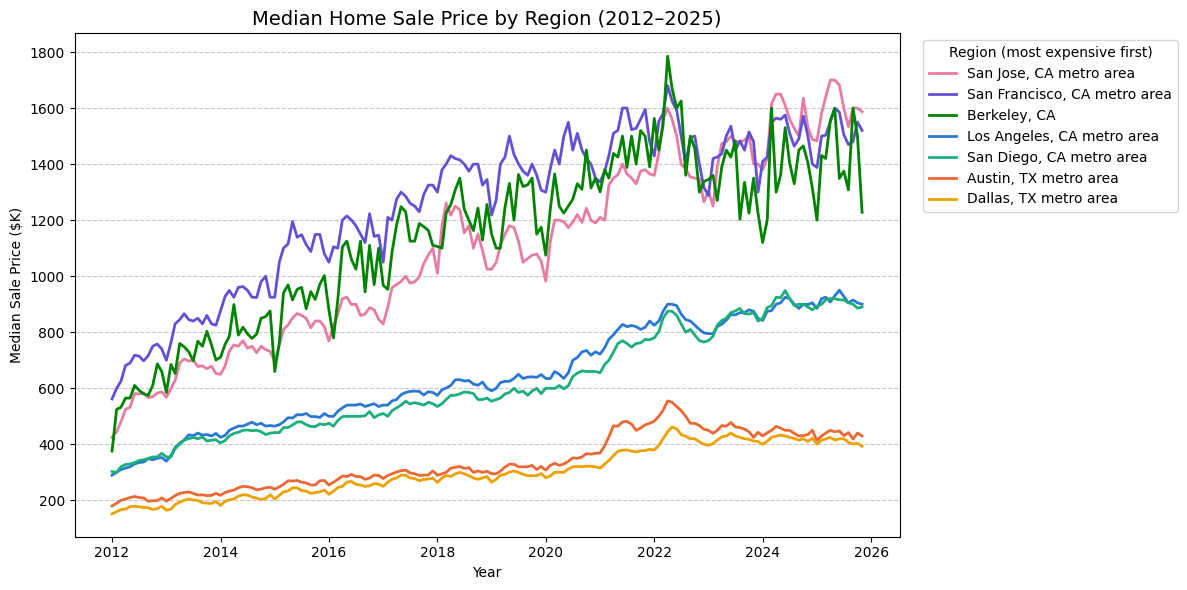

In [33]:
#line chart: monthly median price by region
plt.figure(figsize=(12,6))

#legend order = most expensive to least expensive today, so it matches the lines from top to bottom
legend_order = price_table.index

for region in legend_order:
    region_data = RF_df[RF_df['Region'] == region]
    plt.plot(region_data['Month of Period End'],
             region_data['Median Sale Price'],
             color=region_colors[region],
             linewidth=2,
             label=region)

plt.title('Median Home Sale Price by Region (2012–2025)', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Median Sale Price ($K)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Region (most expensive first)')
plt.tight_layout()
plt.show()

### Finding: two price tiers, and California costs 2 to 4 times as much as Texas

- **Texas is the budget tier.** Dallas averages \$411K and Austin \$435K in 2025.
- **California is a different league.** LA and San Diego sit around \$910K, and the Bay Area (Berkeley, San Francisco, San Jose) runs \$1.4M to \$1.6M.
- **Every market more than doubled since 2012**, from 2.2x (Austin, San Francisco) to 3.0x (San Jose).
- **San Jose overtook San Francisco.** San Francisco was the most expensive market in 2012, but it grew the slowest, and San Jose is now the priciest.
- **Notice the Texas lines after 2022:** they rose fast during the pandemic, then bent downward. Section 6 looks at who fell after 2022 and by how much.

## 6. Q2: After the 2022 rate hikes, which markets fell, and which held up?
Mortgage rates rose sharply in 2022. This section measures how far each market's price has fallen from its own peak.

A single month can spike (especially Berkeley, which is one city rather than a metro area), so prices are smoothed with a **3-month rolling average** before finding the peak.

In [34]:
#peak price vs latest price for each region, using a 3-month rolling average
drop_rows = []

for region in RF_df['Region'].unique():
    region_data = RF_df[RF_df['Region'] == region].sort_values('Month of Period End').copy()

    #3-month rolling average smooths out one-month spikes
    region_data['Price 3M Avg'] = region_data['Median Sale Price'].rolling(3).mean()

    peak_row = region_data.loc[region_data['Price 3M Avg'].idxmax()]
    latest_row = region_data.iloc[-1]

    drop_rows.append({
        'Region': region,
        'Peak Month': peak_row['Month of Period End'].strftime('%b %Y'),
        'Peak Price ($K)': round(peak_row['Price 3M Avg']),
        'Latest Price ($K)': round(latest_row['Price 3M Avg']),
        'Change From Peak (%)': round((latest_row['Price 3M Avg'] / peak_row['Price 3M Avg'] - 1) * 100, 1)
    })

drop_table = pd.DataFrame(drop_rows).sort_values('Change From Peak (%)')
print("Latest = Sep to Nov 2025 average")
drop_table

Latest = Sep to Nov 2025 average


,Region,Peak Month,Peak Price ($K),Latest Price ($K),Change From Peak (%)
0,"Austin, TX metro area",Jun 2022,547,430,-21.4
1,"Berkeley, CA",Jun 2022,1685,1443,-14.4
2,"Dallas, TX metro area",Jun 2022,454,399,-12.0
5,"San Francisco, CA metro area",Jun 2022,1632,1517,-7.1
6,"San Jose, CA metro area",Jun 2025,1694,1596,-5.8
4,"San Diego, CA metro area",Jun 2024,932,892,-4.3
3,"Los Angeles, CA metro area",Jul 2025,936,907,-3.1


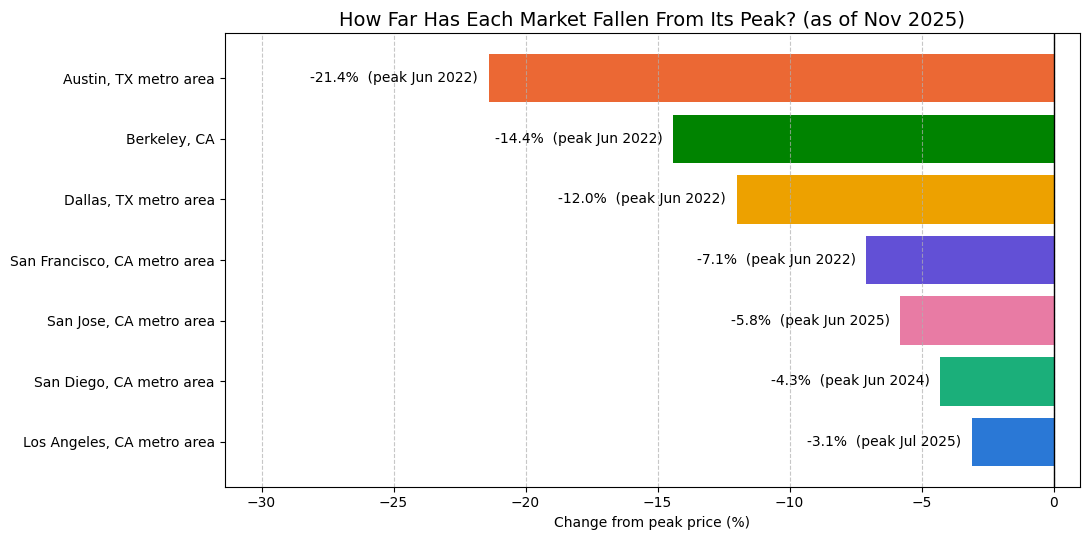

In [35]:
#bar chart: % change from each market's peak
plt.figure(figsize=(11,5.5))

bars = plt.barh(drop_table['Region'],
                drop_table['Change From Peak (%)'],
                color=[region_colors[r] for r in drop_table['Region']])

#label each bar with the % drop and the peak month
for bar, pct, month in zip(bars, drop_table['Change From Peak (%)'], drop_table['Peak Month']):
    plt.text(bar.get_width() - 0.4, bar.get_y() + bar.get_height() / 2,
             f"{pct}%  (peak {month})",
             va='center', ha='right', fontsize=10)

plt.axvline(0, color='black', linewidth=1)
plt.title('How Far Has Each Market Fallen From Its Peak? (as of Nov 2025)', fontsize=14)
plt.xlabel('Change from peak price (%)')
plt.xlim(drop_table['Change From Peak (%)'].min() - 10, 1)
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Finding: cheap is not the same as safe
- **Austin fell the most:** down 21% from its mid-2022 peak (\$547K to \$430K), roughly \$117K off a typical home. The second-cheapest market had the biggest drop.
- **The split is about timing.** Every market that peaked in mid-2022 (Austin, Berkeley, Dallas, San Francisco) is still well below that peak. LA, San Diego and San Jose kept rising through the rate hikes and set new highs in 2024 and 2025.
- **What it means for the uncle:** Texas costs less than half as much, but its prices are still sliding. Southern California costs about twice as much, but has barely moved.
- **Smoothing matters.** With single-month prices, Berkeley shows a 31% drop, because its peak was a one-month spike. The 3-month average puts it at 14%.

*Each "peak month" is the end of a 3-month window. For example, Jun 2022 means the average of April, May and June 2022.*

In [49]:
#yearly price change (%) for each region, based on the yearly average price from Section 5
yearly_change = (yearly_price.pct_change(axis=1) * 100).round(1)

#2012 has no previous year to compare with, so drop it
yearly_change = yearly_change.drop(columns=2012)

#same row order as earlier charts: cheapest market on top
yearly_change = yearly_change.loc[region_order]
yearly_change

Year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Region,,,,,,,,,,,,,
"Dallas, TX metro area",11.6,8.9,11.0,9.1,9.7,3.2,1.9,6.4,17.9,16.1,-0.9,0.3,-2.2
"Austin, TX metro area",8.5,9.4,9.0,7.4,5.4,3.8,2.9,8.7,31.4,11.6,-9.9,-2.0,-1.9
"San Diego, CA metro area",20.2,8.4,6.1,6.6,8.1,5.9,2.3,8.5,17.5,10.5,3.4,6.6,0.5
"Los Angeles, CA metro area",25.9,11.6,7.4,7.4,8.0,6.8,2.8,8.5,17.2,6.4,-0.6,5.7,2.4
"San Jose, CA metro area",23.1,10.4,12.0,6.2,13.1,17.4,-5.2,7.4,13.5,6.9,0.2,8.3,4.0
"Berkeley, CA",25.6,12.4,12.1,11.6,11.6,7.5,1.6,4.2,10.7,6.4,-11.7,2.6,3.0
"San Francisco, CA metro area",19.7,14.4,17.2,4.4,8.5,10.6,-0.8,4.3,5.2,0.1,-4.4,4.3,0.8


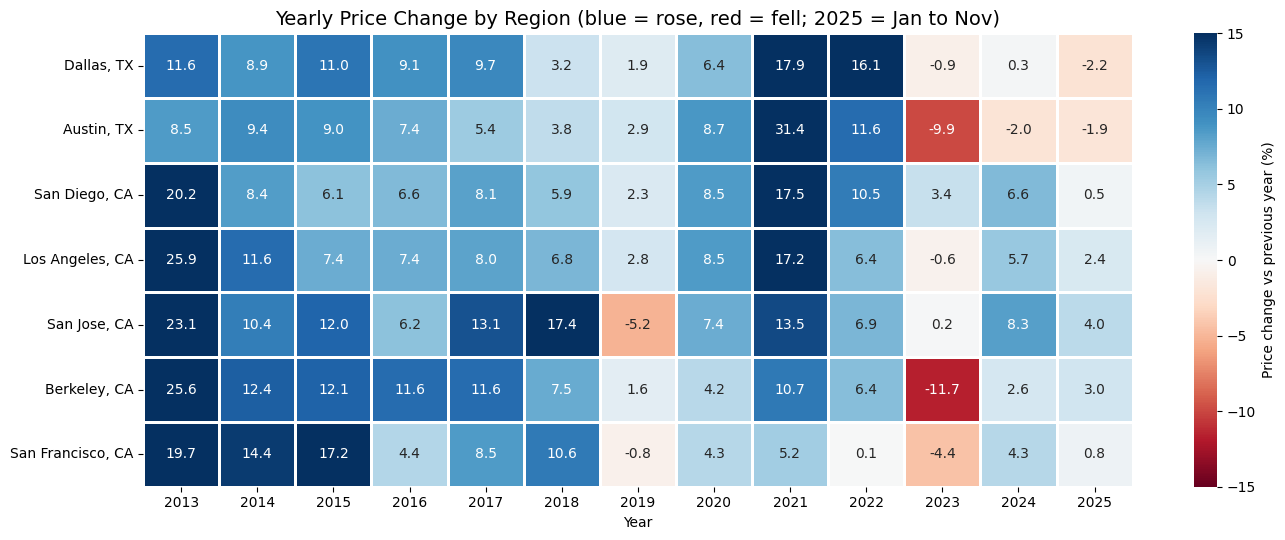

In [50]:
#heatmap: blue = prices rose that year, red = prices fell
plt.figure(figsize=(14,5.5))
sns.heatmap(yearly_change,
            cmap='RdBu',
            center=0,
            vmin=-15,
            vmax=15,
            annot=True,
            fmt='.1f',
            linewidths=1,
            linecolor='white',
            cbar_kws={'label': 'Price change vs previous year (%)'})

#shorter region names on the y-axis
plt.yticks(ticks=[i + 0.5 for i in range(len(yearly_change))],
           labels=[r.replace(' metro area', '') for r in yearly_change.index],
           rotation=0)

plt.title('Yearly Price Change by Region (blue = rose, red = fell; 2025 = Jan to Nov)', fontsize=14)
plt.xlabel('Year')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Finding: Austin had the biggest boom and the biggest bust, and Texas is the only place still falling
- **Austin's 2021 was the hottest year in the whole table:** prices jumped 31% in a single year, then fell 10% in 2023.
- **2023 was the correction year:** 5 of 7 markets fell, led by Berkeley (-11.7%) and Austin (-9.9%).
- **By 2025, California has turned blue again, but Texas has not.** Austin (-1.9%) and Dallas (-2.2%) are the only markets still falling. Section 8 looks at a likely reason: Texas has far more homes for sale than before the pandemic.

*Each cell compares that year's average price with the previous year's. 2025 covers January to November.*

## 7. Q3: Is each market a buyer's market or a seller's market right now?
Two measures show who has the upper hand:
- **Days on Market:** how fast homes sell. Fewer days = buyers are competing.
- **Sale-to-List ratio:** sale price divided by asking price. Above 1.0 = homes sell over asking (seller's market). Below 1.0 = buyers negotiate the price down (buyer's market).

This section compares 2021 (the bidding-war year) with 2025 (January to November).

In [36]:
#average Days on Market and Sale-to-List in 2021 vs 2025
compare_df = RF_df[RF_df['Year'].isin([2021, 2025])]
market_table = compare_df.groupby(['Region', 'Year'])[['Days on Market', 'Average Sale To List']].mean().round(3).unstack()
market_table

Days on Market         Average Sale To List  \
Year                                   2021    2025                 2021   
Region                                                                     
Austin, TX metro area                31.333  79.727                1.048   
Berkeley, CA                         14.167  17.091                1.201   
Dallas, TX metro area                21.750  59.091                1.017   
Los Angeles, CA metro area           34.833  50.182                1.025   
San Diego, CA metro area             11.917  33.455                1.021   
San Francisco, CA metro area         20.333  22.182                1.068   
San Jose, CA metro area              13.250  17.273                1.065   

                                     
Year                           2025  
Region                               
Austin, TX metro area         0.972  
Berkeley, CA                  1.181  
Dallas, TX metro area         0.975  
Los Angeles, CA metro area    0.997  
San Diego, CA metro area      0.990  
San Francisco, CA metro area  1.046  
San Jose, CA metro area       1.033

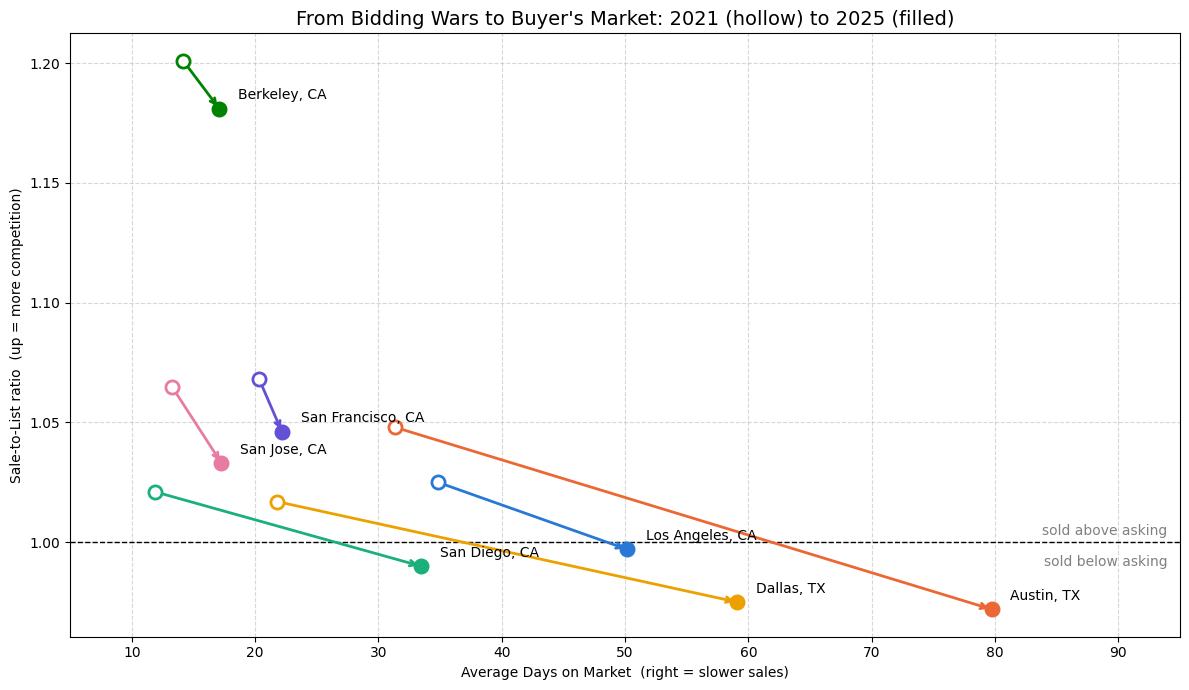

In [37]:
#arrow chart: how each market moved from 2021 (hollow dot) to 2025 (filled dot)
plt.figure(figsize=(12,7))

for region in region_colors:
    dom_2021 = market_table.loc[region, ('Days on Market', 2021)]
    dom_2025 = market_table.loc[region, ('Days on Market', 2025)]
    stl_2021 = market_table.loc[region, ('Average Sale To List', 2021)]
    stl_2025 = market_table.loc[region, ('Average Sale To List', 2025)]
    color = region_colors[region]

    #arrow from 2021 to 2025
    plt.annotate('', xy=(dom_2025, stl_2025), xytext=(dom_2021, stl_2021),
                 arrowprops=dict(arrowstyle='->', color=color, linewidth=2))

    #2021 = hollow dot, 2025 = filled dot
    plt.scatter(dom_2021, stl_2021, s=90, facecolors='white', edgecolors=color, linewidths=2, zorder=3)
    plt.scatter(dom_2025, stl_2025, s=110, color=color, zorder=3)

    #label at the 2025 dot
    plt.text(dom_2025 + 1.5, stl_2025 + 0.004, region.replace(' metro area', ''), fontsize=10)

#asking price line
plt.axhline(1.0, color='black', linestyle='--', linewidth=1)
plt.text(94, 1.003, 'sold above asking', fontsize=10, color='gray', ha='right')
plt.text(94, 0.990, 'sold below asking', fontsize=10, color='gray', ha='right')

plt.title("From Bidding Wars to Buyer's Market: 2021 (hollow) to 2025 (filled)", fontsize=14)
plt.xlabel('Average Days on Market  (right = slower sales)')
plt.ylabel('Sale-to-List ratio  (up = more competition)')
plt.xlim(5, 95)
plt.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Finding: every market cooled, but only Texas and Southern California turned in buyers' favor
- **In 2021, all 7 markets sold above asking.** Every arrow points down and to the right: slower sales and less bidding everywhere by 2025.
- **3 markets now sell below asking:** Austin (0.97), Dallas (0.98) and San Diego (0.99). LA sits right at asking (1.00). Buyers in these markets can negotiate.
- **Austin changed the most:** homes went from selling in 31 days to 80 days, about 2.5 times slower.
- **The Bay Area barely moved.** Homes still sell in 17 to 22 days and above asking, and Berkeley still averages 18% over asking.
- **What it means for the uncle:** in Texas and Southern California he would have time and room to negotiate. In the Bay Area he would likely be in a bidding war.

## 8. Q4: Is supply growing or shrinking, and does it explain the price drops?
Supply is compared between 2019 (the last normal year before the pandemic) and 2025 (January to November).

**Months of supply** = Inventory / Homes Sold per month. It answers: *at the current pace of sales, how many months would it take to sell every home on the market?*
A common real-estate rule of thumb: under about 4 months favors sellers, over about 6 months favors buyers.
Because it is a ratio, it can be compared across markets of very different sizes.

In [38]:
#supply in 2019 vs 2025
supply_df = RF_df[RF_df['Year'].isin([2019, 2025])].copy()
supply_df['Months of Supply'] = supply_df['Inventory'] / supply_df['Homes Sold']

yearly_supply = supply_df.groupby(['Region', 'Year'])[['Inventory', 'Homes Sold', 'Months of Supply']].mean().unstack()

supply_table = pd.DataFrame()
supply_table['Inventory Change (%)'] = ((yearly_supply['Inventory'][2025] / yearly_supply['Inventory'][2019] - 1) * 100).round(0)
supply_table['Homes Sold Change (%)'] = ((yearly_supply['Homes Sold'][2025] / yearly_supply['Homes Sold'][2019] - 1) * 100).round(0)
supply_table['Months of Supply 2019'] = yearly_supply['Months of Supply'][2019].round(1)
supply_table['Months of Supply 2025'] = yearly_supply['Months of Supply'][2025].round(1)

supply_table = supply_table.sort_values('Inventory Change (%)', ascending=False)
supply_table

,Inventory Change (%),Homes Sold Change (%),Months of Supply 2019,Months of Supply 2025
Region,,,,
"Austin, TX metro area",94.0,-20.0,2.5,5.8
"Berkeley, CA",46.0,-6.0,1.3,1.9
"Dallas, TX metro area",37.0,-7.0,3.4,4.9
"San Francisco, CA metro area",22.0,-2.0,1.8,2.2
"Los Angeles, CA metro area",-5.0,-27.0,3.3,4.2
"San Diego, CA metro area",-19.0,-33.0,2.4,2.9
"San Jose, CA metro area",-23.0,-13.0,2.0,1.8


In [39]:
#does supply growth line up with the price drop from Section 6?
supply_table['Change From Peak (%)'] = drop_table.set_index('Region')['Change From Peak (%)']

correlation = supply_table['Inventory Change (%)'].corr(supply_table['Change From Peak (%)'])
print("Correlation between inventory change and price change from peak:", round(correlation, 2))
print("Note: only 7 markets, so this shows a pattern, not proof")

Correlation between inventory change and price change from peak: -0.95
Note: only 7 markets, so this shows a pattern, not proof


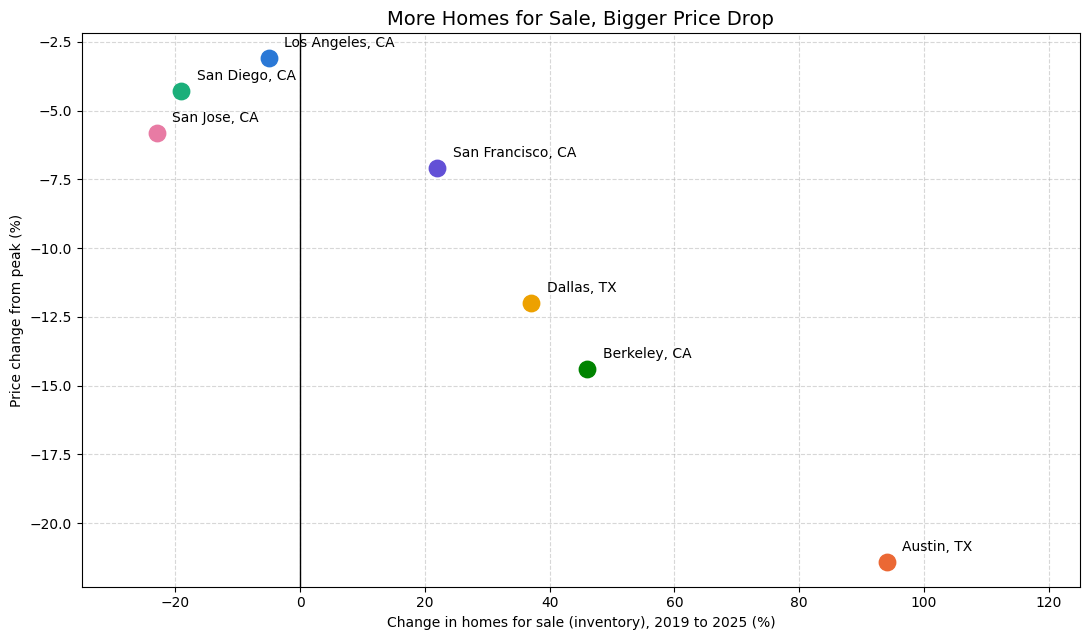

In [40]:
#scatter: inventory change since 2019 vs price change from peak
plt.figure(figsize=(11,6.5))

for region in supply_table.index:
    x = supply_table.loc[region, 'Inventory Change (%)']
    y = supply_table.loc[region, 'Change From Peak (%)']
    plt.scatter(x, y, s=140, color=region_colors[region], zorder=3)
    plt.text(x + 2.5, y + 0.4, region.replace(' metro area', ''), fontsize=10)

plt.axvline(0, color='black', linewidth=1)
plt.title('More Homes for Sale, Bigger Price Drop', fontsize=14)
plt.xlabel('Change in homes for sale (inventory), 2019 to 2025 (%)')
plt.ylabel('Price change from peak (%)')
plt.xlim(-35, 125)
plt.grid(linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Finding: the more homes piled up, the more prices fell
- **Austin's inventory nearly doubled (+94%) while sales fell 20%.** Months of supply went from 2.5 to 5.8, close to the 6-month line where buyers have the advantage.
- **The markets that held their price have fewer homes for sale than in 2019:** San Jose -23%, San Diego -19%, LA -5%.
- **Across the 7 markets, inventory growth and price drop line up closely** (correlation -0.95, and still -0.88 with Austin removed).
- **Caveat:** 7 markets is a small sample, and correlation is not causation. Factors such as new construction, migration after the pandemic, and mortgage rates are not in this data. The pattern fits basic supply and demand, but this data alone cannot prove the cause.
- **This ties Sections 6 and 7 together:** Texas prices are sliding and buyers have room to negotiate because there are far more homes for sale.

## 9. Other Findings
I wonder what are some other interesting findings that could make sense of the market or completely irrelevant

In [41]:
#seasonality: average Days on Market, Sale-to-List and price by calendar month (all regions, all years)
season_df = RF_df.copy()

#price relative to that region's average for the same year (1.05 = 5% above the year's average)
season_df['Price vs Year Avg'] = season_df['Median Sale Price'] / season_df.groupby(['Region', 'Year'])['Median Sale Price'].transform('mean')

season_table = season_df.groupby('Month')[['Days on Market', 'Average Sale To List', 'Price vs Year Avg']].mean().round(3)
season_table

,Days on Market,Average Sale To List,Price vs Year Avg
Month,,,
1,42.643,1.008,0.905
2,33.510,1.028,0.944
3,26.173,1.036,0.987
4,22.949,1.044,1.019
5,22.735,1.043,1.032
6,23.469,1.039,1.039
7,24.969,1.034,1.024
8,27.173,1.029,1.012
9,29.439,1.027,1.006


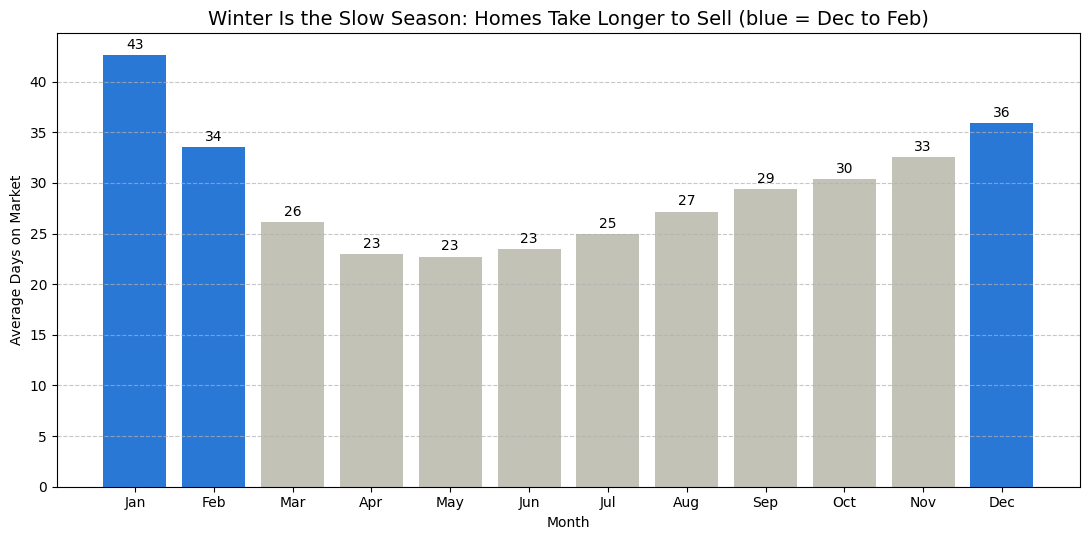

In [42]:
#bar chart: average Days on Market by month, winter months highlighted
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
winter_months = [12, 1, 2]
bar_colors = ['#2a78d6' if m in winter_months else '#c3c2b7' for m in season_table.index]

plt.figure(figsize=(11,5.5))
bars = plt.bar(month_names, season_table['Days on Market'], color=bar_colors)

#label each bar with its value
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.6,
             round(bar.get_height()), ha='center', fontsize=10)

plt.title('Winter Is the Slow Season: Homes Take Longer to Sell (blue = Dec to Feb)', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Average Days on Market')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [43]:
#Berkeley: how often does a home sell above asking?
berkeley = RF_df[RF_df['Region'] == 'Berkeley, CA']
share_above = (berkeley['Average Sale To List'] > 1).mean() * 100

print("Months where Berkeley sold above asking:", round(share_above, 1), "%")
print("Typical (median) Sale-to-List:", berkeley['Average Sale To List'].median())

#April 2022: price 1785 ($K) at a ratio of 1.371, so the asking price was about 1785 / 1.371
peak = berkeley[berkeley['Month of Period End'] == '2022-04-01']
peak_price = peak['Median Sale Price'].iloc[0]
peak_ratio = peak['Average Sale To List'].iloc[0]
print("April 2022: sold for", peak_price, "($K), about", round(peak_price - peak_price / peak_ratio), "($K) above asking")

Months where Berkeley sold above asking: 99.4 %
Typical (median) Sale-to-List: 1.153
April 2022: sold for 1785 ($K), about 483 ($K) above asking


In [44]:
#Dallas: highest number of homes for sale in each year
dallas_metro = RF_df[RF_df['Region'] == 'Dallas, TX metro area']
print(dallas_metro.groupby('Year')['Inventory'].max())

Year
2012    18391
2013    15133
2014    14104
2015    13837
2016    14216
2017    16066
2018    18588
2019    20732
2020    16499
2021     9891
2022    14942
2023    15664
2024    22604
2025    28397
Name: Inventory, dtype: int64


### Fun findings
- **Winter is the buyer's season.** In January, homes take 43 days to sell on average, almost twice as long as in April and May (23 days). Bidding is weakest too (Sale-to-List 1.01 vs 1.04), and January prices run about 10% below the year's average. Part of that price gap is the normal upward trend within a year, but December is not cheap, so the January dip is more than trend.
- **Berkeley almost never sells at asking.** 99% of months sold above asking, typically 15% over. In April 2022, the typical Berkeley home sold for \$1.785M, about \$483K above its asking price.
- **Dallas has more homes for sale than ever in this data.** July 2025 hit 28,397 homes for sale, 54% more than the 2012 high, when the market was still recovering from the housing crash.

## 10. Dead Ends: What Did Not Work
Three things that looked promising but did not hold up. They are kept here because ruling them out shaped how the rest of the analysis was done.

In [45]:
#dead end 1: do more expensive markets sell faster? Check the price vs Days on Market correlation within each region
for region in region_order:
    region_data = RF_df[RF_df['Region'] == region]
    corr = region_data['Median Sale Price'].corr(region_data['Days on Market'])
    print(region, ":", round(corr, 2))

Dallas, TX metro area : -0.13
Austin, TX metro area : 0.4
San Diego, CA metro area : -0.41
Los Angeles, CA metro area : 0.07
San Jose, CA metro area : -0.17
Berkeley, CA : -0.37
San Francisco, CA metro area : 0.01


In [46]:
#dead end 2: can raw counts be compared across regions?
print("Average homes sold per month:")
print(RF_df.groupby('Region')['Homes Sold'].mean().round(0).sort_values())

Average homes sold per month:
Region
Berkeley, CA                      57.0
San Francisco, CA metro area     959.0
San Jose, CA metro area         1257.0
Austin, TX metro area           2748.0
San Diego, CA metro area        2825.0
Dallas, TX metro area           5276.0
Los Angeles, CA metro area      5657.0
Name: Homes Sold, dtype: float64


In [47]:
#dead end 3: is month-over-month (MoM) price change a useful signal?
#2021 was a boom year: how often did MoM still show a price drop?
data_2021 = RF_df[RF_df['Year'] == 2021]
share_negative = (data_2021['Median Sale Price MoM'] < 0).mean() * 100

print("Average year-over-year price change in 2021:", round(data_2021['Median Sale Price YoY'].mean() * 100, 1), "%")
print("Share of 2021 months where MoM showed a price drop:", round(share_negative), "%")

Average year-over-year price change in 2021: 16.3 %
Share of 2021 months where MoM showed a price drop: 35 %


### What did not work
- **"More expensive homes sell faster" does not hold up.** With all regions mixed together, price and Days on Market have a correlation of -0.49, which looks like a real pattern. But that pattern comes from the regions, not the price: the Bay Area is expensive and fast (\$1.1M to \$1.3M, 17 to 22 days on average), while Texas is cheap and slower (about \$300K, about 40 days). Within each region, the correlation ranges from -0.41 to +0.40, with no consistent direction.
- **Raw counts cannot be compared across regions.** Berkeley sells about 57 homes a month and LA about 5,657. Comparing raw counts measures market size, not demand. That is why Section 8 uses ratios (% change, months of supply).
- **Month-over-month change is too noisy.** In 2021, prices rose 16% year over year, yet 35% of monthly readings showed a drop. Yearly averages and year-over-year changes tell the real story.

## 11. So, Where Should My Uncle Buy?
One table brings together everything from Sections 5 to 8. Markets are sorted from cheapest to most expensive.

Market type is a simple label based on the 2025 Sale-to-List ratio: below 0.985 = buyer's market, 0.985 to 1.01 = balanced, above 1.01 = seller's market.

In [48]:
#one summary table from Sections 5 to 8
summary_table = pd.DataFrame(index=price_table.index)
summary_table['2025 Price ($K)'] = price_table['2025 ($K)']
summary_table['Change From Peak (%)'] = drop_table.set_index('Region')['Change From Peak (%)']
summary_table['Days on Market 2025'] = market_table[('Days on Market', 2025)].round(0)
summary_table['Sale-to-List 2025'] = market_table[('Average Sale To List', 2025)].round(3)
summary_table['Months of Supply 2025'] = supply_table['Months of Supply 2025']
summary_table['Inventory Change vs 2019 (%)'] = supply_table['Inventory Change (%)']

#simple market type label based on Sale-to-List
market_type = []
for ratio in summary_table['Sale-to-List 2025']:
    if ratio < 0.985:
        market_type.append("Buyer's market")
    elif ratio <= 1.01:
        market_type.append('Balanced')
    else:
        market_type.append("Seller's market")
summary_table['Market Type'] = market_type

summary_table = summary_table.sort_values('2025 Price ($K)')
summary_table

,2025 Price ($K),Change From Peak (%),Days on Market 2025,Sale-to-List 2025,Months of Supply 2025,Inventory Change vs 2019 (%),Market Type
Region,,,,,,,
"Dallas, TX metro area",411.0,-12.0,59.0,0.975,4.9,37.0,Buyer's market
"Austin, TX metro area",435.0,-21.4,80.0,0.972,5.8,94.0,Buyer's market
"San Diego, CA metro area",905.0,-4.3,33.0,0.990,2.9,-19.0,Balanced
"Los Angeles, CA metro area",916.0,-3.1,50.0,0.997,4.2,-5.0,Balanced
"Berkeley, CA",1415.0,-14.4,17.0,1.181,1.9,46.0,Seller's market
"San Francisco, CA metro area",1514.0,-7.1,22.0,1.046,2.2,22.0,Seller's market
"San Jose, CA metro area",1610.0,-5.8,17.0,1.033,1.8,-23.0,Seller's market


### Recommendation
**Short answer: Dallas is the best value right now.** It has the lowest price, it is a buyer's market, and it has fallen less than Austin.

Three scenarios, depending on what matters most to him:

**1. Budget first: Dallas (or Austin)**
- Lowest prices in the data: Dallas \$411K, Austin \$435K (2025 average).
- Buyer's market: homes take 2 to almost 3 months to sell and go for less than asking, so there is room to negotiate.
- Dallas over Austin: Austin offers the bigger discount from its peak (-21%), but with almost 6 months of supply it is the shakier market. Dallas has fallen less (-12%). Both were still down about 2% in 2025, so there is no rush: waiting or negotiating hard can pay off.

**2. He wants California: LA or San Diego**
- About \$910K, roughly twice the price of Texas, but prices have held within 3% to 4% of their peak.
- LA gives more room to negotiate (50 days on market, 4.2 months of supply). San Diego is tighter (33 days, 2.9 months), with fewer homes for sale than in 2019.

**3. The Bay Area: only if being there matters more than cost**
- \$1.4M to \$1.6M, homes sell in about 2 to 3 weeks and above asking, and Berkeley still averages 18% over asking. Expect bidding wars.

These recommendations cover the housing market only. His other concerns (community, cost of living) are in Section 12.

## 12. Limitations and Future Work

**Limitations**
- **Monthly medians, not individual homes.** The median mixes all home types (houses, condos, townhomes), so a shift in what sells can move the median even if prices do not change.
- **7 markets, Jan 2012 to Nov 2025.** 2025 is a partial year (January to November). Berkeley is a single city while the others are metro areas.
- **Correlation, not causation.** The supply and price link in Section 8 rests on only 7 markets.
- **Housing only.** Property tax (much higher in Texas), home insurance, mortgage rates and everyday cost of living are not in this data, and they can change which market is truly cheaper.

**Future work: the uncle's other questions**
- **Community:** add U.S. Census (American Community Survey) data on Asian population by metro area, since this was one of his main concerns.
- **Total monthly cost:** combine price with property tax, insurance and current mortgage rates to compare the real monthly cost of owning in each market.
- **Retiree fit:** add cost-of-living and healthcare access data for a fuller retirement comparison.

## 13. Export for Tableau
Two clean files for the dashboard:
- **housing_monthly_clean.csv:** one row per region per month, for trend charts.
- **housing_region_summary.csv:** one row per region, for comparison charts and summary cards.

In [52]:
#monthly file: one row per region per month
export_monthly = RF_df[['Region', 'Month of Period End', 'Year', 'Month',
                        'Median Sale Price', 'Homes Sold', 'New Listings', 'Inventory',
                        'Days on Market', 'Average Sale To List']].copy()

#extra columns that make Tableau easier
export_monthly['Region Short'] = export_monthly['Region'].str.replace(' metro area', '', regex=False)
export_monthly['State'] = export_monthly['Region Short'].str[-2:]
export_monthly['Months of Supply'] = (export_monthly['Inventory'] / export_monthly['Homes Sold']).round(2)

export_monthly.to_csv('/content/drive/MyDrive/Project portfolio/Housing project/housing_monthly_clean.csv', index=False)
print(export_monthly.shape)
export_monthly.head()

(1169, 13)


,Region,Month of Period End,Year,Month,Median Sale Price,Homes Sold,New Listings,Inventory,Days on Market,Average Sale To List,Region Short,State,Months of Supply
0,"Austin, TX metro area",2012-01-01,2012,1,180,1181,2167,6871,74,0.962,"Austin, TX",TX,5.82
1,"Austin, TX metro area",2012-02-01,2012,2,190,1397,2559,6975,73,0.967,"Austin, TX",TX,4.99
2,"Austin, TX metro area",2012-03-01,2012,3,200,2071,3392,7429,58,0.973,"Austin, TX",TX,3.59
3,"Austin, TX metro area",2012-04-01,2012,4,205,2118,3376,7737,38,0.977,"Austin, TX",TX,3.65
4,"Austin, TX metro area",2012-05-01,2012,5,210,2580,3490,7968,36,0.977,"Austin, TX",TX,3.09


In [53]:
#summary file: one row per region
export_summary = summary_table.reset_index()
export_summary['Region Short'] = export_summary['Region'].str.replace(' metro area', '', regex=False)
export_summary['State'] = export_summary['Region Short'].str[-2:]

export_summary.to_csv('/content/drive/MyDrive/Project portfolio/Housing project/housing_region_summary.csv', index=False)
print(export_summary.shape)
export_summary

(7, 10)


,Region,2025 Price ($K),Change From Peak (%),Days on Market 2025,Sale-to-List 2025,Months of Supply 2025,Inventory Change vs 2019 (%),Market Type,Region Short,State
0,"Dallas, TX metro area",411.0,-12.0,59.0,0.975,4.9,37.0,Buyer's market,"Dallas, TX",TX
1,"Austin, TX metro area",435.0,-21.4,80.0,0.972,5.8,94.0,Buyer's market,"Austin, TX",TX
2,"San Diego, CA metro area",905.0,-4.3,33.0,0.990,2.9,-19.0,Balanced,"San Diego, CA",CA
3,"Los Angeles, CA metro area",916.0,-3.1,50.0,0.997,4.2,-5.0,Balanced,"Los Angeles, CA",CA
4,"Berkeley, CA",1415.0,-14.4,17.0,1.181,1.9,46.0,Seller's market,"Berkeley, CA",CA
5,"San Francisco, CA metro area",1514.0,-7.1,22.0,1.046,2.2,22.0,Seller's market,"San Francisco, CA",CA
6,"San Jose, CA metro area",1610.0,-5.8,17.0,1.033,1.8,-23.0,Seller's market,"San Jose, CA",CA
